In [2]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier

## Data Collection

In [3]:
df=pd.read_csv("../dataset/student-mat.csv", sep=";")

In [4]:
print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [5]:
print("Shape:", df.shape)

Shape: (395, 33)


In [6]:
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [7]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [9]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [10]:
def categorize_grade(grade):

    if grade <= 9:
        return "Low"

    elif grade <= 13:
        return "Average"

    else:
        return "High"


df["Performance"] = df["G3"].apply(
    categorize_grade
)

print("\nPerformance Distribution:")
print(df["Performance"].value_counts())


Performance Distribution:
Performance
Average    165
Low        130
High       100
Name: count, dtype: int64


## EXPLORATORY DATA ANALYSIS

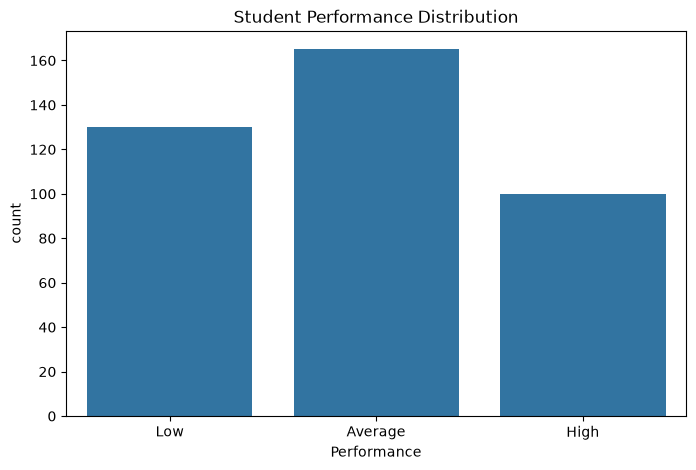

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Performance",
    order=["Low", "Average", "High"]
)
plt.title("Student Performance Distribution")
plt.show()


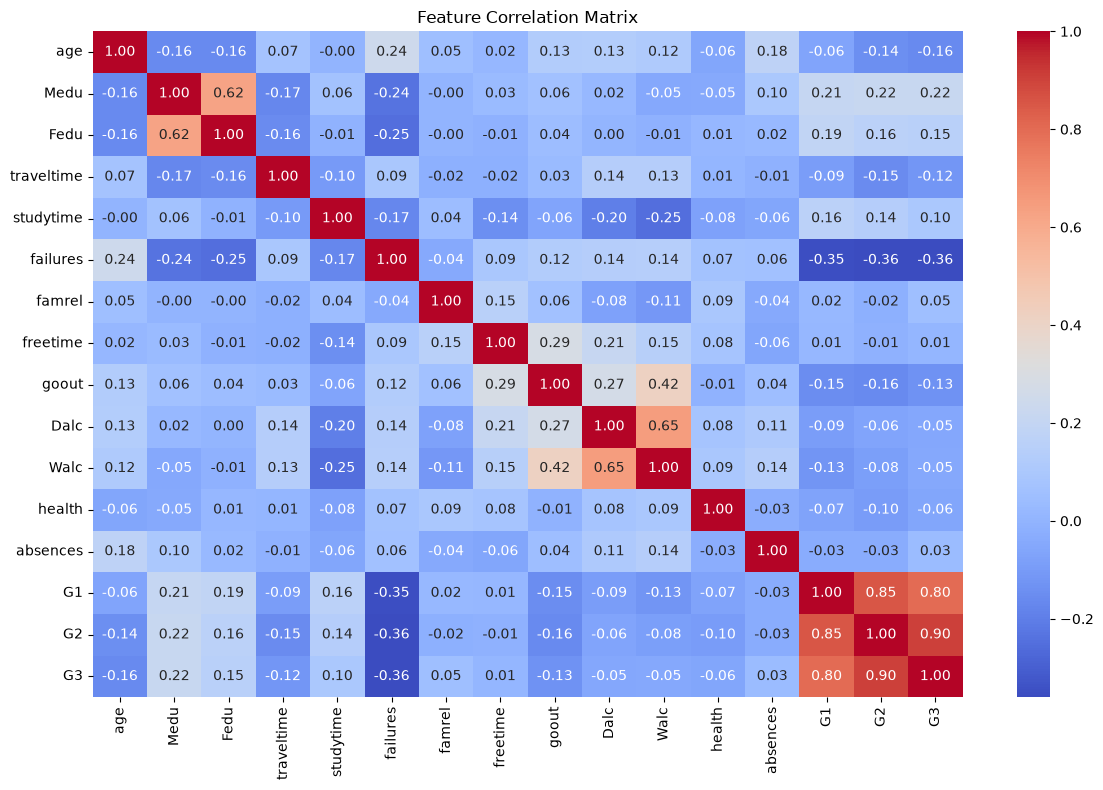

In [12]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### EDA: how grades, study habits and absences relate to performance

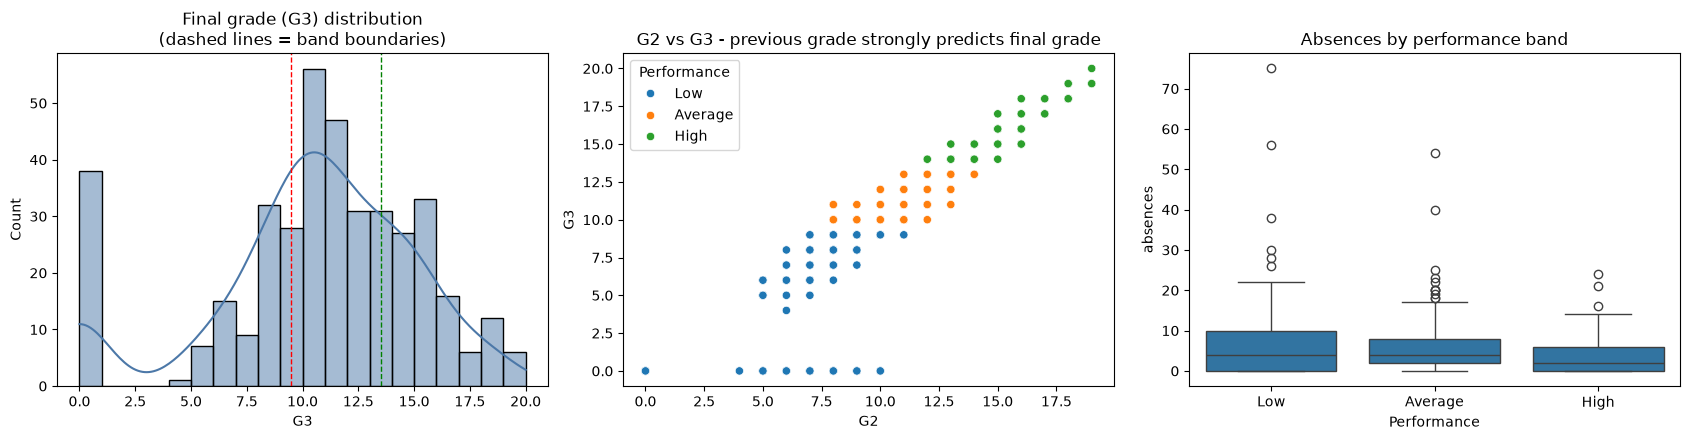

In [13]:
order = ["Low", "Average", "High"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df["G3"], bins=20, kde=True, ax=axes[0], color="#4c78a8")
axes[0].axvline(9.5, color="red", ls="--", lw=1)
axes[0].axvline(13.5, color="green", ls="--", lw=1)
axes[0].set_title("Final grade (G3) distribution\n(dashed lines = band boundaries)")

sns.scatterplot(data=df, x="G2", y="G3", hue="Performance", hue_order=order, ax=axes[1])
axes[1].set_title("G2 vs G3 - previous grade strongly predicts final grade")

sns.boxplot(data=df, x="Performance", y="absences", order=order, ax=axes[2])
axes[2].set_title("Absences by performance band")

plt.tight_layout()
plt.show()

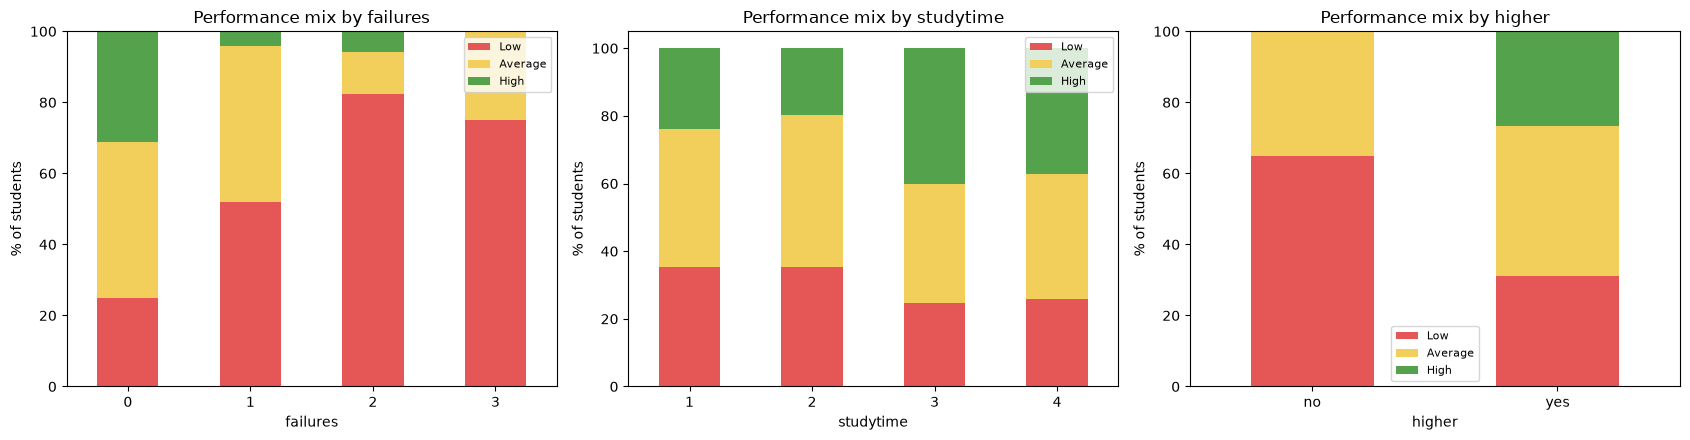

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, col in zip(axes, ["failures", "studytime", "higher"]):
    (pd.crosstab(df[col], df["Performance"], normalize="index")[order] * 100).plot(
        kind="bar", stacked=True, ax=ax, color=["#e45756", "#f2cf5b", "#54a24b"]
    )
    ax.set_title(f"Performance mix by {col}")
    ax.set_ylabel("% of students")
    ax.set_xlabel(col)
    ax.legend(title="", fontsize=8)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## Feature and Target Separation

In [16]:
X = df.drop(
    columns=["G3", "Performance"]
)

y = df["Performance"]

print("\nInput Features:", X.shape)
print("Target:", y.shape)


Input Features: (395, 32)
Target: (395,)


## TRAIN-TEST-VALIDATION SPLIT

In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset Split:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Dataset Split:
Training: (276, 32)
Validation: (59, 32)
Testing: (60, 32)


## IDENTIFY NUMERICAL AND CATEGORICAL

In [18]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


## PREPROCESSING

In [19]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])


X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = np.asarray(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed.toarray()
    if hasattr(X_val_processed, "toarray")
    else X_val_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    dtype=np.float32
)

In [20]:
label_mapping = {
    "Low": 0,
    "Average": 1,
    "High": 2
}

y_train_encoded = y_train.map(label_mapping).to_numpy()
y_val_encoded = y_val.map(label_mapping).to_numpy()
y_test_encoded = y_test.map(label_mapping).to_numpy()

## MODEL

In [21]:
# ==========================================
# STEP 1: BUILD DEEP NEURAL NETWORK
# ==========================================

input_features = X_train_processed.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_features,)),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(32, activation="relu"),

    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nDNN Model Architecture:")
model.summary()


DNN Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,987 (70.26 KB)

 Trainable params: 17,987 (70.26 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="models/best_student_dnn.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

## TRAINING

In [23]:
history = model.fit(
    X_train_processed,
    y_train_encoded,

    validation_data=(
        X_val_processed,
        y_val_encoded
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/100
1/9 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.2812 - loss: 1.3193
Epoch 1: val_loss improved from None to 1.04992, saving model to models/best_student_dnn.keras

Epoch 1: finished saving model to models/best_student_dnn.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.3877 - loss: 1.1695 - val_accuracy: 0.4407 - val_loss: 1.0499 - learning_rate: 0.0010
Epoch 2/100
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5312 - loss: 1.0286
Epoch 2: val_loss improved from 1.04992 to 0.97962, saving model to models/best_student_dnn.keras

Epoch 2: finished saving model to models/best_student_dnn.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4928 - loss: 1.0236 - val_accuracy: 0.5424 - val_loss: 0.9796 - learning_rate: 0.0010
Epoch 3/100
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.3438 - loss: 0.9972
Epoch 3: val_loss improved from 0.97962 to 0.89224, saving model to models/best_student_dnn.keras

Epoch 3: finished saving model to models/best_stude

In [24]:
model = tf.keras.models.load_model(
    "models/best_student_dnn.keras"
)

test_loss, test_accuracy = model.evaluate(
    X_test_processed,
    y_test_encoded,
    verbose=1
)

print("DNN Test Accuracy:", test_accuracy)
print("DNN Test Loss:", test_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8167 - loss: 0.4001 
DNN Test Accuracy: 0.8166666626930237
DNN Test Loss: 0.40010175108909607


In [25]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_pred = np.argmax(
    model.predict(X_test_processed, verbose=0),
    axis=1
)

print(classification_report(
    y_test_encoded,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Average", "High"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred))

              precision    recall  f1-score   support

         Low       0.86      0.90      0.88        20
     Average       0.82      0.72      0.77        25
        High       0.76      0.87      0.81        15

    accuracy                           0.82        60
   macro avg       0.81      0.83      0.82        60
weighted avg       0.82      0.82      0.81        60

Confusion Matrix:
[[18  2  0]
 [ 3 18  4]
 [ 0  2 13]]


## TRAINING ON RANDOM FOREST

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train_processed,
    y_train_encoded
)

rf_predictions = rf_model.predict(X_test_processed)

rf_accuracy = accuracy_score(
    y_test_encoded,
    rf_predictions
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8833333333333333


In [27]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Deep Neural Network", "Random Forest"],
    "Test Accuracy": [test_accuracy, rf_accuracy]
})

print(comparison)

                 Model  Test Accuracy
0  Deep Neural Network       0.816667
1        Random Forest       0.883333


## MODEL EVALUATION

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Actual labels shape: (60,)
DNN predictions shape: (60,)
Random Forest predictions shape: (60,)

========== MODEL ACCURACY ==========
DNN Accuracy: 81.67 %
Random Forest Accuracy: 88.33 %

========== DNN CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.86      0.90      0.88        20
           1       0.82      0.72      0.77        25
           2       0.76      0.87      0.81        15

    accuracy                           0.82        60
   macro avg       0.81      0.83      0.82        60
weighted avg       0.82      0.82      0.81        60


========== RANDOM FOREST CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.83      0.95      0.88        20
           1       0.91      0.80      0.85        25
           2       0.93      0.93      0.93        15

    accuracy                           0.88        60
   macro avg  

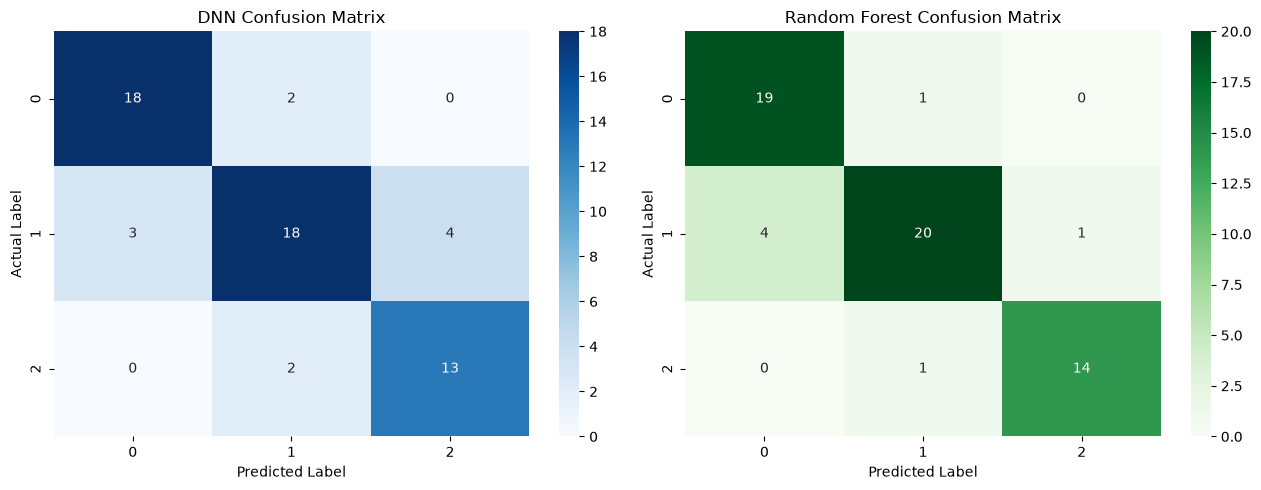


========== FINAL MODEL COMPARISON ==========
              Model  Accuracy  Precision  Recall  F1 Score
Deep Neural Network     81.67      81.78   81.67     81.50
      Random Forest     88.33      88.75   88.33     88.25


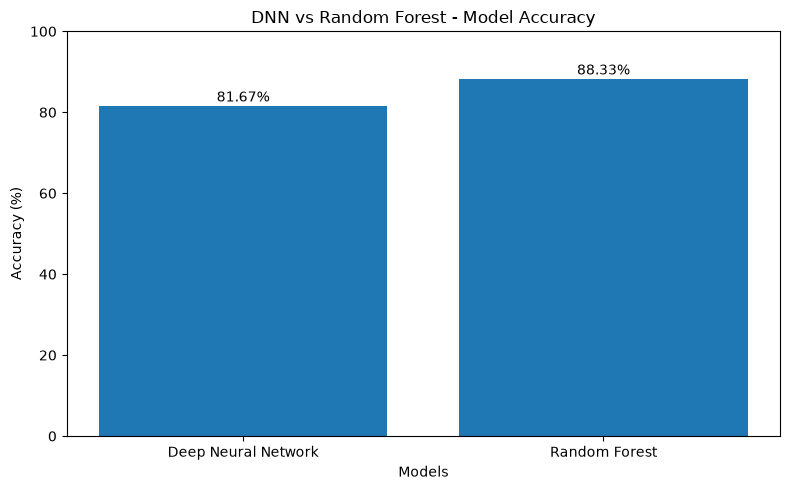

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ==========================================
# 1. DNN MODEL PREDICTIONS
# ==========================================

dnn_probabilities = model.predict(X_test_processed)

# Select class with highest probability
y_pred_dnn = np.argmax(dnn_probabilities, axis=1)


# ==========================================
# 2. RANDOM FOREST PREDICTIONS
# ==========================================

y_pred_rf = rf_model.predict(X_test_processed)

# ==========================================
# 3. ACTUAL TEST LABELS
# ==========================================

y_actual = np.asarray(y_test_encoded)

if y_actual.ndim == 2:
    y_actual = np.argmax(y_actual, axis=1)
else:
    y_actual = y_actual.ravel()

# ==========================================
# 4. CHECK SHAPES
# ==========================================

print("Actual labels shape:", y_actual.shape)
print("DNN predictions shape:", y_pred_dnn.shape)
print("Random Forest predictions shape:", y_pred_rf.shape)

assert len(y_actual) == len(y_pred_dnn)
assert len(y_actual) == len(y_pred_rf)

# ==========================================
# 5. ACCURACY
# ==========================================

dnn_accuracy = accuracy_score(y_actual, y_pred_dnn)
rf_accuracy = accuracy_score(y_actual, y_pred_rf)

print("\n========== MODEL ACCURACY ==========")

print("DNN Accuracy:", round(dnn_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

# ==========================================
# 6. CLASSIFICATION REPORTS
# ==========================================

print("\n========== DNN CLASSIFICATION REPORT ==========")

print(classification_report(
    y_actual,
    y_pred_dnn,
    zero_division=0
))

print("\n========== RANDOM FOREST CLASSIFICATION REPORT ==========")

print(classification_report(
    y_actual,
    y_pred_rf,
    zero_division=0
))

# ==========================================
# 7. CONFUSION MATRICES
# ==========================================

cm_dnn = confusion_matrix(y_actual, y_pred_dnn)
cm_rf = confusion_matrix(y_actual, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm_dnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("DNN Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

# ==========================================
# 8. PRECISION, RECALL AND F1 COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": ["Deep Neural Network", "Random Forest"],

    "Accuracy": [
        dnn_accuracy * 100,
        rf_accuracy * 100
    ],

    "Precision": [
        precision_score(y_actual, y_pred_dnn,
                        average="weighted", zero_division=0) * 100,
        precision_score(y_actual, y_pred_rf,
                        average="weighted", zero_division=0) * 100
    ],

    "Recall": [
        recall_score(y_actual, y_pred_dnn,
                     average="weighted", zero_division=0) * 100,
        recall_score(y_actual, y_pred_rf,
                     average="weighted", zero_division=0) * 100
    ],

    "F1 Score": [
        f1_score(y_actual, y_pred_dnn,
                 average="weighted", zero_division=0) * 100,
        f1_score(y_actual, y_pred_rf,
                 average="weighted", zero_division=0) * 100
    ]
})

print("\n========== FINAL MODEL COMPARISON ==========")

print(comparison.round(2).to_string(index=False))

# ==========================================
# 9. ACCURACY COMPARISON GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("DNN vs Random Forest - Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.xlabel("Models")
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


## TUNING RANDOM FOREST

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Define parameter combinations
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

# 2. Initialize Random Forest
rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

# 3. Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# 5. Train on training data only
grid_search.fit(
    X_train_processed,
    y_train_encoded
)

# 6. Best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid_search.best_score_)

# 7. Get best model
best_rf_model = grid_search.best_estimator_

# 8. Test on unseen data
best_rf_predictions = best_rf_model.predict(
    X_test_processed
)

from sklearn.metrics import accuracy_score

best_rf_accuracy = accuracy_score(
    y_test_encoded,
    best_rf_predictions
)

print("\nTuned Random Forest Test Accuracy:",
      best_rf_accuracy * 100, "%")

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}

Best Cross Validation Accuracy:
0.8696103896103896

Tuned Random Forest Test Accuracy: 88.33333333333333 %


## TUNING DNN

In [32]:
import tensorflow as tf
import numpy as np
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [34]:
# ==========================================
# DNN TUNING SETUP: search grid + model builder
# ==========================================
tf.keras.utils.set_random_seed(42)   # makes the tuning results repeatable

hidden_units_list = [32, 64, 128]
dropout_rates     = [0.2, 0.3, 0.4]
learning_rates    = [0.001, 0.0005]
batch_sizes       = [16, 32]

print("Configurations to try:",
      len(hidden_units_list) * len(dropout_rates) * len(learning_rates) * len(batch_sizes))


def build_dnn(hidden_units, dropout_rate, learning_rate):
    """3-class DNN: two hidden layers (units and units/2) with dropout."""
    dnn = Sequential([
        Input(shape=(X_train_processed.shape[1],)),

        Dense(hidden_units, activation="relu"),
        Dropout(dropout_rate),

        Dense(hidden_units // 2, activation="relu"),
        Dropout(dropout_rate),

        Dense(3, activation="softmax")
    ])

    dnn.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return dnn

Configurations to try: 36


In [35]:
results = []

best_accuracy = 0
best_dnn_model = None
best_history = None

early_stop = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True
)

for units in hidden_units_list:
    for dropout in dropout_rates:
        for lr in learning_rates:
            for batch in batch_sizes:

                print("\nTraining configuration:")
                print("Hidden Units:", units)
                print("Dropout:", dropout)
                print("Learning Rate:", lr)
                print("Batch Size:", batch)

                tf.keras.backend.clear_session()

                dnn = build_dnn(
                    hidden_units=units,
                    dropout_rate=dropout,
                    learning_rate=lr
                )

                history = dnn.fit(
                    X_train_processed,
                    y_train_encoded,
                    validation_split=0.2,
                    epochs=100,
                    batch_size=batch,
                    callbacks=[early_stop],
                    verbose=0
                )

                val_accuracy = max(history.history["val_accuracy"])

                results.append({
                    "Hidden Units": units,
                    "Dropout": dropout,
                    "Learning Rate": lr,
                    "Batch Size": batch,
                    "Validation Accuracy": val_accuracy
                })

                if val_accuracy > best_accuracy:
                    best_accuracy = val_accuracy
                    best_dnn_model = dnn
                    best_history = history

                print("Validation Accuracy:", round(val_accuracy, 4))

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
)

print(results_df.to_string(index=False))

print("\nBest DNN Configuration:")
print(results_df.iloc[0])


Training configuration:
Hidden Units: 32
Dropout: 0.2
Learning Rate: 0.001
Batch Size: 16

Validation Accuracy: 0.7679

Training configuration:
Hidden Units: 32
Dropout: 0.2
Learning Rate: 0.001
Batch Size: 32
Validation Accuracy: 0.5357

Training configuration:
Hidden Units: 32
Dropout: 0.2
Learning Rate: 0.0005
Batch Size: 16
Validation Accuracy: 0.3571

Training configuration:
Hidden Units: 32
Dropout: 0.2
Learning Rate: 0.0005
Batch Size: 32
Validation Accuracy: 0.375

Training configuration:
Hidden Units: 32
Dropout: 0.3
Learning Rate: 0.001
Batch Size: 16
Validation Accuracy: 0.75

Training configuration:
Hidden Units: 32
Dropout: 0.3
Learning Rate: 0.001
Batch Size: 32
Validation Accuracy: 0.7857

Training configuration:
Hidden Units: 32
Dropout: 0.3
Learning Rate: 0.0005
Batch Size: 16
Validation Accuracy: 0.3929

Training configuration:
Hidden Units: 32
Dropout: 0.3
Learning Rate: 0.0005
Batch Size: 32
Validation Accuracy: 0.6071

Training configuration:
Hidden Units: 32
Drop

In [36]:
import os

os.makedirs("models", exist_ok=True)

best_dnn_model.save("models/tuned_student_dnn.keras")

print("Best DNN model saved successfully!")

Best DNN model saved successfully!


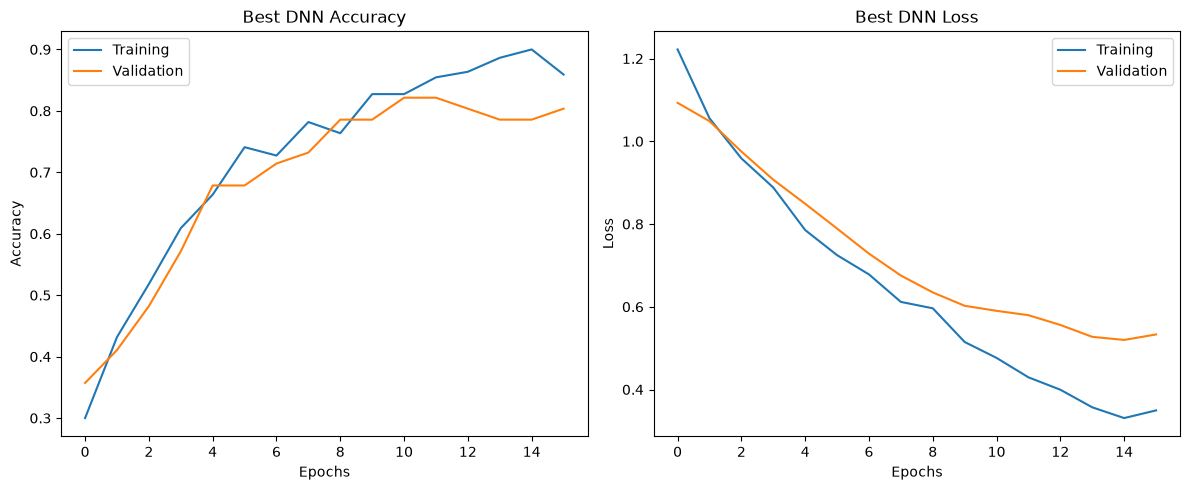

In [37]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["accuracy"], label="Training")
plt.plot(best_history.history["val_accuracy"], label="Validation")
plt.title("Best DNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(best_history.history["loss"], label="Training")
plt.plot(best_history.history["val_loss"], label="Validation")
plt.title("Best DNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

test_loss, test_accuracy = best_dnn_model.evaluate(
    X_test_processed,
    y_test_encoded,
    verbose=1
)

y_pred_dnn = np.argmax(
    best_dnn_model.predict(X_test_processed),
    axis=1
)

print("Final DNN Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Final DNN Test Loss:", test_loss)

print("\nClassification Report:")
print(classification_report(y_test_encoded, y_pred_dnn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_dnn))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.7500 - loss: 0.5445 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Final DNN Test Accuracy: 75.0 %
Final DNN Test Loss: 0.5444739460945129

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.95      0.83        20
           1       0.81      0.52      0.63        25
           2       0.72      0.87      0.79        15

    accuracy                           0.75        60
   macro avg       0.76      0.78      0.75        60
weighted avg       0.76      0.75      0.74        60


Confusion Matrix:
[[19  1  0]
 [ 7 13  5]
 [ 0  2 13]]


## FINAL MODEL COMPARISON (all four models)

========== FINAL COMPARISON ON TEST SET ==========
                Model  Accuracy  Precision  Recall  F1 (weighted)  F1 (macro)
Random Forest (tuned)     88.33      88.36   88.33          88.32       88.95
        Random Forest     88.33      88.75   88.33          88.25       88.94
       DNN (baseline)     81.67      81.78   81.67          81.50       81.88
          DNN (tuned)     75.00      76.27   75.00          73.66       74.94

Selected final model: Random Forest (tuned)


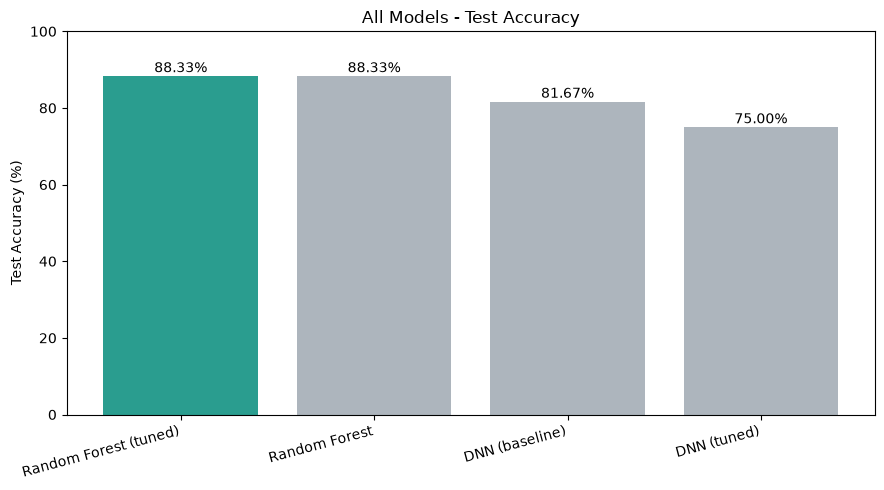

In [39]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

class_names = ["Low", "Average", "High"]

# Predictions of all four models on the SAME untouched test set
baseline_dnn_pred = np.argmax(model.predict(X_test_processed, verbose=0), axis=1)
tuned_dnn_pred    = np.argmax(best_dnn_model.predict(X_test_processed, verbose=0), axis=1)

candidates = {
    "DNN (baseline)":      {"pred": baseline_dnn_pred,        "model": model,          "kind": "keras"},
    "DNN (tuned)":         {"pred": tuned_dnn_pred,           "model": best_dnn_model, "kind": "keras"},
    "Random Forest":       {"pred": rf_model.predict(X_test_processed), "model": rf_model,      "kind": "sklearn"},
    "Random Forest (tuned)": {"pred": best_rf_predictions,    "model": best_rf_model,  "kind": "sklearn"},
}

rows = []
for name, c in candidates.items():
    p = c["pred"]
    rows.append({
        "Model": name,
        "Accuracy":    accuracy_score(y_test_encoded, p) * 100,
        "Precision":   precision_score(y_test_encoded, p, average="weighted", zero_division=0) * 100,
        "Recall":      recall_score(y_test_encoded, p, average="weighted", zero_division=0) * 100,
        "F1 (weighted)": f1_score(y_test_encoded, p, average="weighted", zero_division=0) * 100,
        "F1 (macro)":  f1_score(y_test_encoded, p, average="macro", zero_division=0) * 100,
    })

final_comparison = (
    pd.DataFrame(rows)
    .sort_values(["Accuracy", "F1 (macro)"], ascending=False)
    .reset_index(drop=True)
)

print("========== FINAL COMPARISON ON TEST SET ==========")
print(final_comparison.round(2).to_string(index=False))

# Pick the winner (accuracy first, macro-F1 breaks ties)
best_name = final_comparison.loc[0, "Model"]
best_info = candidates[best_name]
print(f"\nSelected final model: {best_name}")

# Bar chart
plt.figure(figsize=(9, 5))
bars = plt.bar(final_comparison["Model"], final_comparison["Accuracy"],
               color=["#2a9d8f" if m == best_name else "#adb5bd" for m in final_comparison["Model"]])
plt.ylim(0, 100)
plt.ylabel("Test Accuracy (%)")
plt.title("All Models - Test Accuracy")
plt.xticks(rotation=15, ha="right")
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 1,
             f"{b.get_height():.2f}%", ha="center")
plt.tight_layout()
plt.show()

## DETAILED EVALUATION OF THE SELECTED MODEL

========== Random Forest (tuned) - CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

         Low       0.86      0.90      0.88        20
     Average       0.88      0.84      0.86        25
        High       0.93      0.93      0.93        15

    accuracy                           0.88        60
   macro avg       0.89      0.89      0.89        60
weighted avg       0.88      0.88      0.88        60



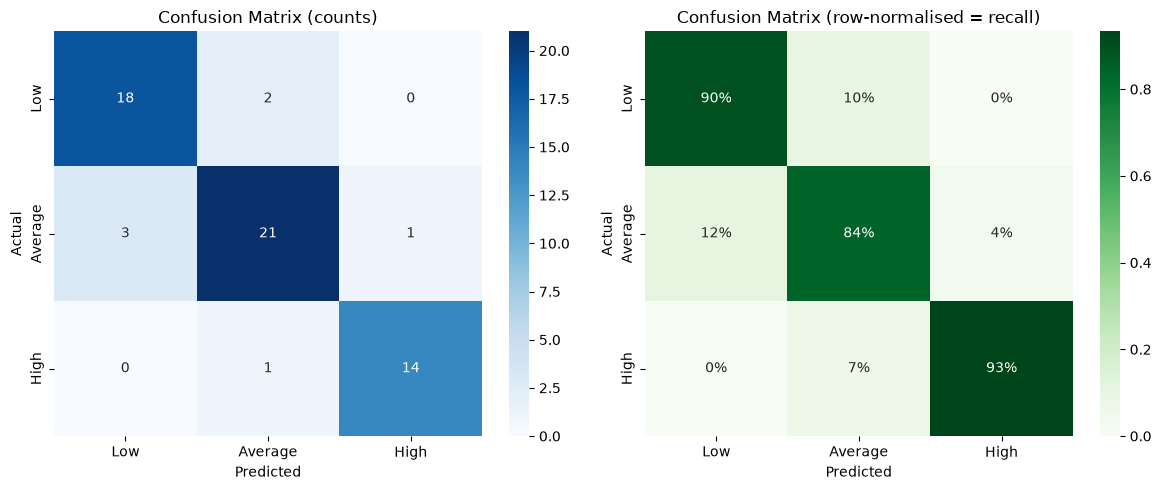

Misclassified: 7 / 60
  of which only one band away (e.g. Average <-> High): 7


In [40]:
best_pred = best_info["pred"]

print(f"========== {best_name} - CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test_encoded, best_pred,
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_test_encoded, best_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title("Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Greens", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Confusion Matrix (row-normalised = recall)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Where does the model go wrong? Mostly neighbouring grade bands?
errors = (best_pred != y_test_encoded)
off_by_one = (np.abs(best_pred - y_test_encoded) == 1) & errors
print(f"Misclassified: {errors.sum()} / {len(errors)}")
print(f"  of which only one band away (e.g. Average <-> High): {off_by_one.sum()}")

## ROBUSTNESS CHECK - CROSS-VALIDATION

The test set has only 60 students, so one lucky/unlucky split can move accuracy a lot. Cross-validation on the whole dataset (with preprocessing inside the pipeline, so there is no leakage) gives a steadier estimate.

In [41]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.base import clone

y_all = df["Performance"].map(label_mapping).to_numpy()

rf_params = grid_search.best_params_
cv_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("rf", RandomForestClassifier(random_state=42, class_weight="balanced", **rf_params))
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(cv_pipeline, X, y_all, cv=skf, scoring="accuracy", n_jobs=-1)

print("5-fold CV accuracy per fold:", np.round(cv_scores * 100, 2))
print(f"Mean CV accuracy: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f})")
print(f"Hold-out test accuracy of tuned RF: {accuracy_score(y_test_encoded, best_rf_predictions) * 100:.2f}%")

5-fold CV accuracy per fold: [86.08 87.34 87.34 82.28 91.14]
Mean CV accuracy: 86.84% (+/- 2.84)
Hold-out test accuracy of tuned RF: 88.33%


## FEATURE IMPORTANCE (Random Forest)

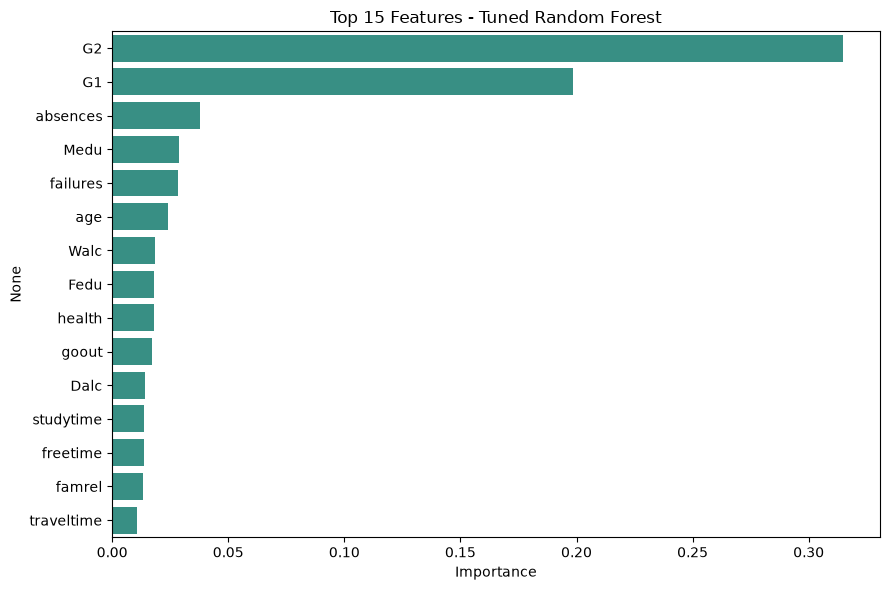

G2            0.3150
G1            0.1984
absences      0.0378
Medu          0.0288
failures      0.0285
age           0.0241
Walc          0.0186
Fedu          0.0181
health        0.0180
goout         0.0170
Dalc          0.0140
studytime     0.0137
freetime      0.0136
famrel        0.0131
traveltime    0.0107


In [42]:
feature_names = preprocessor.get_feature_names_out()
feature_names = [n.split("__", 1)[-1] for n in feature_names]

importances = pd.Series(best_rf_model.feature_importances_, index=feature_names)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_features.values, y=top_features.index, color="#2a9d8f")
plt.title("Top 15 Features - Tuned Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(top_features.round(4).to_string())

**Reading the result:** `G2` and `G1` (the earlier period grades) usually dominate, because the final grade `G3` is strongly tied to them. 
That is fine for predicting the *final band*, but if the goal is **early warning** (flagging students before any grades exist), 
retrain without `G1`/`G2` and see how much accuracy drops - the next cell does exactly that.

In [43]:
# Optional: "early warning" model that does NOT use G1/G2
early_cols = [c for c in X.columns if c not in ("G1", "G2")]
num_early = [c for c in numerical_features if c in early_cols]
cat_early = [c for c in categorical_features if c in early_cols]

early_pre = ColumnTransformer([
    ("numerical", numerical_pipeline, num_early),
    ("categorical", categorical_pipeline, cat_early)
])

early_model = Pipeline([
    ("preprocessor", early_pre),
    ("rf", RandomForestClassifier(random_state=42, class_weight="balanced", **grid_search.best_params_))
])

early_scores = cross_val_score(early_model, X[early_cols], y_all, cv=skf, scoring="accuracy", n_jobs=-1)
print(f"Without G1/G2 -> mean CV accuracy: {early_scores.mean() * 100:.2f}% (+/- {early_scores.std() * 100:.2f})")
print(f"With    G1/G2 -> mean CV accuracy: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f})")

Without G1/G2 -> mean CV accuracy: 46.58% (+/- 5.85)
With    G1/G2 -> mean CV accuracy: 86.84% (+/- 2.84)


## SAVE THE FINAL MODEL AND PREPROCESSING ARTIFACTS

In [44]:
os.makedirs("models", exist_ok=True)

# 1. Preprocessor (needed to transform raw input in exactly the same way)
joblib.dump(preprocessor, "models/preprocessor.joblib")

# 2. Final model
if best_info["kind"] == "sklearn":
    final_model_path = "models/final_student_model.joblib"
    joblib.dump(best_info["model"], final_model_path)
else:
    final_model_path = "models/final_student_model.keras"
    best_info["model"].save(final_model_path)

# 3. Label mapping + metadata
inverse_label_mapping = {v: k for k, v in label_mapping.items()}

metadata = {
    "final_model": best_name,
    "model_kind": best_info["kind"],
    "model_path": final_model_path,
    "label_mapping": label_mapping,
    "input_columns": X.columns.tolist(),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "grade_bands": {"Low": "G3 <= 9", "Average": "10 <= G3 <= 13", "High": "G3 >= 14"},
    "test_metrics": final_comparison.set_index("Model").loc[best_name].round(2).to_dict(),
    "cv_accuracy_mean": round(float(cv_scores.mean() * 100), 2),
}

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Saved:")
for f in sorted(os.listdir("models")):
    print("  models/" + f)

Saved:
  models/final_student_model.joblib
  models/model_metadata.json
  models/preprocessor.joblib
  models/tuned_student_dnn.keras


## PREDICTING FOR A NEW STUDENT (load from disk)

In [45]:
# Reload everything from disk, exactly as a separate app / API would
with open("models/model_metadata.json") as f:
    meta = json.load(f)

loaded_preprocessor = joblib.load("models/preprocessor.joblib")

if meta["model_kind"] == "sklearn":
    loaded_model = joblib.load(meta["model_path"])
else:
    loaded_model = tf.keras.models.load_model(meta["model_path"])

idx_to_label = {v: k for k, v in meta["label_mapping"].items()}


def predict_student_performance(student: dict) -> dict:
    """
    student : dict with the raw columns of student-mat.csv (except G3),
              e.g. {"school": "GP", "sex": "F", "age": 17, ..., "G1": 11, "G2": 12}
    Missing columns are allowed - the imputers in the pipeline fill them.
    """
    row = pd.DataFrame([student]).reindex(columns=meta["input_columns"])

    processed = loaded_preprocessor.transform(row)
    processed = np.asarray(
        processed.toarray() if hasattr(processed, "toarray") else processed,
        dtype=np.float32
    )

    if meta["model_kind"] == "sklearn":
        probs = loaded_model.predict_proba(processed)[0]
    else:
        probs = loaded_model.predict(processed, verbose=0)[0]

    pred_idx = int(np.argmax(probs))
    return {
        "prediction": idx_to_label[pred_idx],
        "confidence": round(float(probs[pred_idx]) * 100, 2),
        "probabilities": {idx_to_label[i]: round(float(p) * 100, 2) for i, p in enumerate(probs)},
    }


# Demo 1: a real student from the test set
sample = X_test.iloc[0].to_dict()
print("Actual band   :", y_test.iloc[0])
print("Model output  :", predict_student_performance(sample))

# Demo 2: sanity check - the loaded model must reproduce the in-memory test predictions
check_processed = loaded_preprocessor.transform(X_test)
check_processed = np.asarray(
    check_processed.toarray() if hasattr(check_processed, "toarray") else check_processed,
    dtype=np.float32
)
if meta["model_kind"] == "sklearn":
    reloaded_pred = loaded_model.predict(check_processed)
else:
    reloaded_pred = np.argmax(loaded_model.predict(check_processed, verbose=0), axis=1)

print("\nReloaded model test accuracy:",
      round(accuracy_score(y_test_encoded, reloaded_pred) * 100, 2), "%")

Actual band   : High
Model output  : {'prediction': 'High', 'confidence': 75.18, 'probabilities': {'Low': 3.34, 'Average': 21.48, 'High': 75.18}}

Reloaded model test accuracy: 88.33 %


## CONCLUSION

- **Task:** classify students into *Low* (G3 <= 9), *Average* (10-13) and *High* (>= 14) performance bands using the student-mat dataset.
- **Models compared:** a deep neural network and a Random Forest, each before and after hyper-parameter tuning, all evaluated on the same held-out test set (60 students).
- **Result:** the Random Forest beat both DNNs on the test set (about 88% vs 82% for the baseline DNN and 77% for the tuned DNN). 
  Tuning the DNN did *not* help on the test set: its tuning score came from a very small validation split (about 56 rows), so the "best" configuration was partly luck. 
  On tabular data this small, tree ensembles are typically the stronger and more stable choice.
- **Most important features:** see the feature-importance chart above (period grades `G1`/`G2` are expected to dominate). 
  The "early warning" cell shows how accuracy changes when they are removed.
- **Limitations:** small dataset (395 rows), a small test set, and a single course (Mathematics). 
  Cross-validated accuracy is the more trustworthy number to report.
- **Deployment artifacts:** `models/final_student_model.*`, `models/preprocessor.joblib`, `models/model_metadata.json`, plus the `predict_student_performance()` helper above.